## Polynomial Regression

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [39]:
df=pd.read_csv('score.csv')

In [40]:
df.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


In [41]:
print(df.head())
print(df.shape)
print(df.isna().sum())

   Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30
(25, 2)
Hours     0
Scores    0
dtype: int64


### X <-> y

In [42]:
X=df[['Hours']]
y=df['Scores']

### Train / Test split

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (20, 1)  Test: (5, 1)


### creating the polynomial feature

In [44]:
degree = 4
poly = PolynomialFeatures(degree=degree, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test) 
print(X_train[:3])
print(X_train_poly[:3])

    Hours
9     2.7
13    3.3
1     5.1
[[  2.7      7.29    19.683   53.1441]
 [  3.3     10.89    35.937  118.5921]
 [  5.1     26.01   132.651  676.5201]]


## Model Train

In [45]:
model = LinearRegression()
model.fit(X_train_poly, y_train)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [-2.35235509e+00  2.51283571e+00 -1.37020993e-01 -1.87661571e-03]
Intercept: 18.1143638018874


### Prediction

In [46]:
y_pred=model.predict(X_test_poly)
print('predict', y_pred)

predict [84.44614303 25.72444095 25.72444095 72.25284492 61.29208232]


#### Evaluation

In [47]:
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("R2:", r2, " RMSE:", rmse)

R2: 0.9772199293214372  RMSE: 3.6611191714100726


d:\ML_regression\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


Text(0.5, 1.0, 'Polynomial Regression')

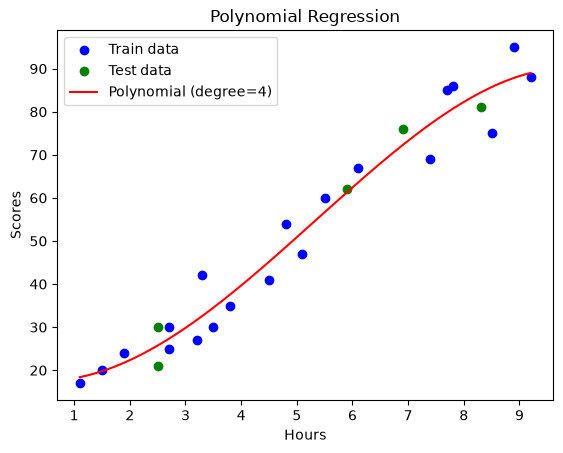

In [48]:
X_range = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
y_curve = model.predict(poly.transform(X_range))
 
plt.scatter(X_train, y_train, color="blue", label="Train data")
plt.scatter(X_test, y_test, color="green", label="Test data")
plt.plot(X_range, y_curve, color="red", label=f"Polynomial (degree={degree})")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.legend()
plt.title("Polynomial Regression")

In [ ]:
hours = 7.5
pred = model.predict(poly.transform([[hours]]))
print(f"{hours} ghante -> {pred[0]:.1f} marks")

7.5 ghante -> 78.1 marks


d:\ML_regression\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
